In [3]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from kneed import KneeLocator
from kneed import find_shape

In [4]:
df = pd.read_csv("creditcard.csv")
df = df.drop("Time", axis=1)
df = df.drop("Class", axis=1)

print(df.head())
print(type(df))
#noise = np.random.normal(5,20, size=df.shape) #  μ = 0(mean), σ = 2(standard deviation), size = length of x or y. Choose μ and σ wisely.
#y_noised = df + noise  # Since both y and noise are numpy arrays of same size, the addition is done element-wise.
#You can adjust the amount of noise by adjusting the mean of the distribution, and the intensity of the noise by adjusting the standard deviation.
#print(y_noised.shape)
#print(y_noised.head())
#print(y_noised["V2"])

         V1        V2        V3        V4        V5        V6        V7  \
0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9       V10  ...       V20       V21       V22       V23  \
0  0.098698  0.363787  0.090794  ...  0.251412 -0.018307  0.277838 -0.110474   
1  0.085102 -0.255425 -0.166974  ... -0.069083 -0.225775 -0.638672  0.101288   
2  0.247676 -1.514654  0.207643  ...  0.524980  0.247998  0.771679  0.909412   
3  0.377436 -1.387024 -0.054952  ... -0.208038 -0.108300  0.005274 -0.190321   
4 -0.270533  0.817739  0.753074  ...  0.408542 -0.009431  0.798278 -0.137458   

        V24       V25       V26       V27       V28  Amount  
0  0.0

In [53]:
df['OutNum'] = 0
old_size = len(df)

for col in df.columns[:-1]:
    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)
    IQR = Q3 - Q1
    lower_bound_iqr = Q1 - 1.5 * IQR
    upper_bound_iqr = Q3 + 1.5 * IQR
    outliers = (df[col] < lower_bound_iqr) | (df[col] > upper_bound_iqr)
    df.loc[outliers, "OutNum"] += 1
    # df[col] = df[col].clip(lower=lower_bound_iqr, upper=upper_bound_iqr)

df = df[df["OutNum"] <= 0.20 * (len(df.columns) - 1)].reset_index(drop=True).iloc[:, :-1] #0.20 is threshold
print((old_size - len(df)) / old_size)

0.05046224285217709


In [33]:
model = IsolationForest(n_estimators=200, contamination='auto', n_jobs=-1, random_state=42)

model.fit(df)
df["noise"] = model.predict(df)

noise = df[df["noise"] == -1]
clean = df[df["noise"] == 1]

print(len(noise) / len(df))
df = clean.drop(columns="noise").reset_index(drop=True)

0.03746926248451569


In [38]:
#determine optimal amount of clusters - silhoutte score/elbow method
#n_init - number of times the k-means algorithm is run with different centroid seeds
#n_clusters - amount of clusters


silhouettes = []
X = StandardScaler().fit_transform(df)

for i in range(2, 11):
    k_means = KMeans(
        n_clusters=i,
        random_state=42,
        init='k-means++',
        max_iter=300
    )

    predicted_labels = k_means.fit_predict(X)
    silhouette = silhouette_score(X, predicted_labels)

    print(f"k={i}: {silhouette}")
    silhouettes.append(silhouette)

KeyboardInterrupt: 

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
<class 'numpy.ndarray'>
[-1  0 -1 ... -1 -1 -1]
Number of clusters: 29
Number of noise points: 110021
38.630019627326575


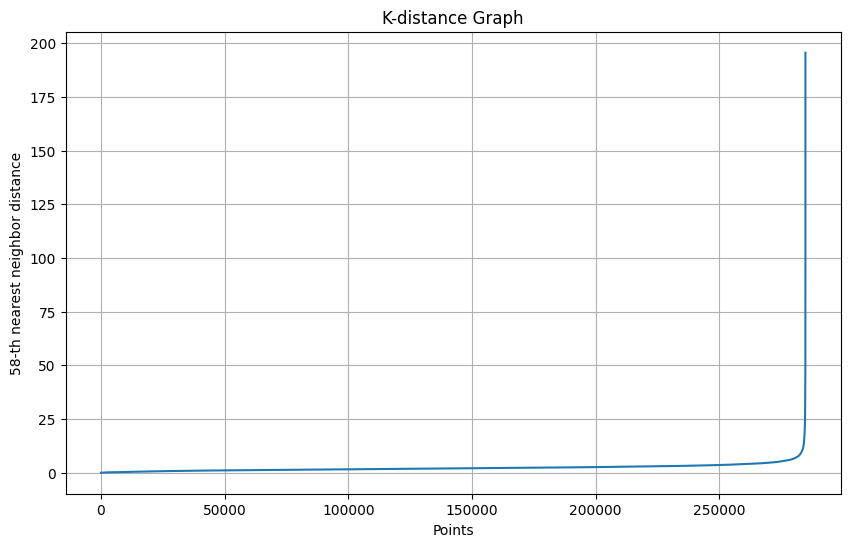

<class 'pandas.DataFrame'>
[[0.00000000e+00 1.99568219e+00 2.01906745e+00 ... 3.30128604e+00
  3.31617966e+00 3.32349822e+00]
 [4.21468485e-08 9.38538856e-01 1.15748553e+00 ... 2.60460236e+00
  2.62482225e+00 2.64667724e+00]
 [0.00000000e+00 2.64241292e+00 3.98145176e+00 ... 6.15329418e+00
  6.16362892e+00 6.18249127e+00]
 ...
 [0.00000000e+00 5.10472416e+00 5.33596243e+00 ... 6.49917323e+00
  6.52575663e+00 6.54082521e+00]
 [0.00000000e+00 2.09601353e+00 3.40494578e+00 ... 5.27758412e+00
  5.29051514e+00 5.29111580e+00]
 [0.00000000e+00 5.09466117e+00 5.17591737e+00 ... 6.94947002e+00
  6.95008107e+00 6.96025702e+00]]
[[  0 857 867 ... 152 507 721]
 [  1 233 209 ... 232 449  77]
 [  2 637 282 ... 214 353  27]
 ...
 [997 897 763 ... 459 196 200]
 [998 486 762 ... 461 289 535]
 [999 884 630 ... 784 864 930]]
Sorted = [ 2.25059776  2.26051274  2.27044053  2.28081698  2.29243686  2.29883306
  2.32861418  2.34285258  2.34445047  2.36795518  2.41015336  2.42582358
  2.44627357  2.46901992  

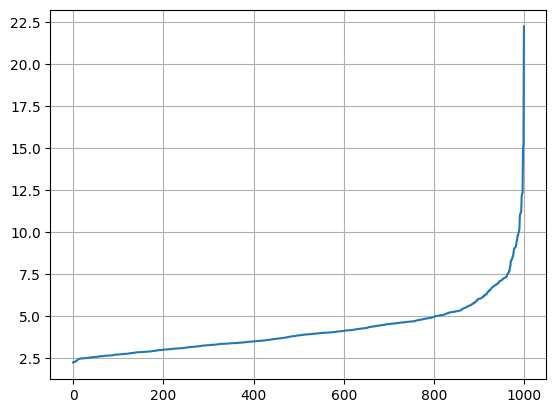

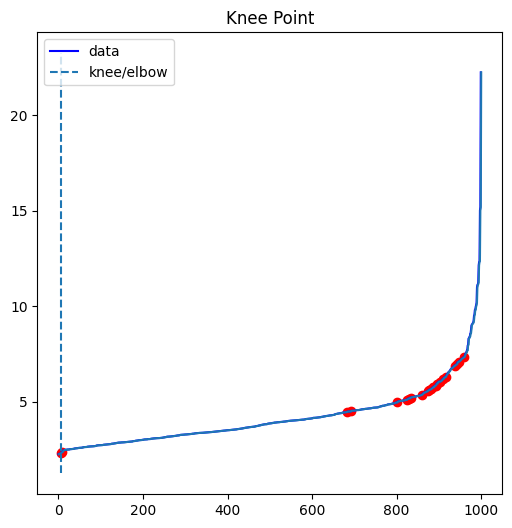

In [10]:
#dbscan = DBSCAN(eps=34, min_samples=340)
#dbscan.fit(df)

print(type(df))
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)
print(type(df))
print(type(df_scaled))


# DBSCAN.
#Take all the values from the kl.all_knees_y and use that for epsilon in a for loop.
epsilon = 3  # Chosen based on k-distance graph
min_samples = 58  # 2 * num_features (2D data)
dbscan = DBSCAN(eps=epsilon, min_samples=min_samples)
clusters = dbscan.fit_predict(df)

  
print(clusters)
# Print number of clusters and noise points
n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)
print(f'Number of clusters: {n_clusters}')
print(f'Number of noise points: {n_noise}')

print(n_noise / len(df) * 100)



#Plot the WHOLE dataset on a graph which isnt very usefull
def plot_k_distance_graph(X, k):
    neigh = NearestNeighbors(n_neighbors=k)
    neigh.fit(X)
    distances, _ = neigh.kneighbors(X)
    distances = np.sort(distances[:, k-1])
    plt.figure(figsize=(10, 6))
    plt.plot(distances)
    plt.xlabel('Points')
    plt.ylabel(f'{k}-th nearest neighbor distance')
    plt.title('K-distance Graph')
    plt.grid()
    plt.show()
   
plot_k_distance_graph(df_scaled, min_samples)


#Plot the first 1000 rows into a line graph
neigh = NearestNeighbors(n_neighbors=min_samples)
print(type(df))

nbrs = neigh.fit(df_scaled[:1000,:])
distances, indices = nbrs.kneighbors(df_scaled[:1000,:])
print(distances)
print(indices)
distances = np.sort(distances[:, min_samples-1])
print(f"Sorted = {distances}")
plt.grid()
plt.plot(distances)
print(f"Shape of distances: {distances.shape}")
print(f"Type for distances: {type(distances)}")
print(f"Number of dimensions for distances: {distances.ndim}")
print(f"Size of distances: {distances.size}")
print(f"Number of dimensions of indices: {indices.ndim}")
print(f"Size of indices: {indices.size}")
print(f"Shape of indices: {indices.shape}")
print(f"Len of distances: {len(distances)}")


#Distances = Only the distances between the nearest point
"""
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.figure(figsize=(20,10))
plt.plot(distances)
plt.title('K-distance Graph',fontsize=20)
plt.xlabel('Data Points sorted by distance',fontsize=14)
plt.ylabel('Epsilon',fontsize=14)
plt.show()
"""

x = np.arange(0, 1000, 1)

direction, curve = find_shape(x, distances)
kl = KneeLocator(x, distances, curve=curve, direction=direction, online=True)
print(f"knee: {kl.knee_y}")
print(f"All knees: {kl.all_knees_y}")
print(f"All elbow: {kl.all_elbows}")
kl.plot_knee()

###ploting the graph to show the red which the algorithm sees
plt.plot(
    np.arange(1, len(distances) + 1),
    distances
)

for knee in kl.all_knees:
    plt.scatter(
        knee,
        distances[knee - 1],
        color="red"
    )

plt.show()
#remove outiels